# 🏏 Mumbai Indians — IPL 2026 Performance Analytics

## Project Overview

This project analyses Mumbai Indians' performance in the available IPL 2026 match data using Python, Pandas, and Matplotlib.

The analysis focuses on match results, batting performance, bowling performance, and innings phases to identify performance patterns and potential areas for improvement.

## Business Problem

What factors are associated with Mumbai Indians' performance in the available IPL 2026 matches, and which areas require improvement?

## Tools and Technologies

- Python
- Pandas
- Matplotlib
- Jupyter Notebook
- Visualisation and exploratory data analysis

## Project Scope

The analysis covers seven Mumbai Indians matches represented in the available dataset. The findings should not be interpreted as a full-season assessment.

## Expected Outcomes

- Evaluate MI's match results.
- Identify leading batting performers.
- Analyse batting and bowling performance across innings phases.
- Compare performance in wins and losses.
- Present findings through charts and concise business recommendations.

## 1. Business Questions

This analysis aims to answer the following questions:

1. How many matches did Mumbai Indians win and lose?
2. What was MI's win rate in the analysed matches?
3. Which MI batters scored the most runs?
4. Which batting phases contributed the most runs?
5. How did MI's bowling performance vary across phases?
6. How did MI's scores differ between wins and losses?
7. What performance areas should be prioritised for improvement?

## 2. Import Libraries

Pandas is used for loading, cleaning, transforming, and analysing tabular data.

Matplotlib is used to create charts that communicate the analysis findings.

In [84]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the Datasets

Load the IPL match-level and ball-by-ball datasets into Pandas DataFrames.

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# Load IPL datasets
matches = pd.read_csv("data/matches.csv")
deliveries = pd.read_csv("data/deliveries.csv")

print("Matches dataset loaded successfully!")
print("Deliveries dataset loaded successfully!")

Matches dataset loaded successfully!
Deliveries dataset loaded successfully!


## 4. Initial Data Inspection

In this section, we examine the structure of the matches and deliveries datasets.

We will:
- View the first five rows.
- Check the number of rows and columns.
- Review column names.
- Understand the data structure before cleaning.

In [86]:
# Inspect the matches dataset
print("MATCHES DATASET")
display(matches.head())

print("Matches shape:", matches.shape)
print("Matches columns:", matches.columns.tolist())

# Inspect the deliveries dataset
print("\nDELIVERIES DATASET")
display(deliveries.head())

print("Deliveries shape:", deliveries.shape)
print("Deliveries columns:", deliveries.columns.tolist())

MATCHES DATASET


,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,match_winner,wb_runs,wb_wickets,balls_left,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,super_over_match
0,1,"March 28, 2026","M. Chinnaswamy Stadium, Bangalore",RCB,SRH,League,RCB,Bowl,201.0,9.0,...,RCB,NaN,6.0,26.0,Jacob Duffy,Ishan Kishan,80.0,Jacob Duffy,3--22,No
1,2,"March 29, 2026","Wankhede Stadium, Mumbai",MI,KKR,League,MI,Bowl,220.0,4.0,...,MI,NaN,6.0,5.0,Shardul Thakur,Ryan Rickelton,81.0,Shardul Thakur,3--39,No
2,3,"March 30, 2026","Barsapara Stadium, Guwahati",RR,CSK,League,RR,Bowl,127.0,10.0,...,RR,NaN,8.0,47.0,Nandre Burger,Vaibhav Sooryavanshi,52.0,Jofra Archer,2--19,No
3,4,"March 31, 2026","New PCA Cricket Stadium, Mullanpur",PBKS,GT,League,PBKS,Bowl,162.0,6.0,...,PBKS,NaN,3.0,5.0,Cooper Connolly,Cooper Connolly,72.0,Prasidh Krishna,3--29,No
4,5,"April 01, 2026","Ekana Cricket Stadium, Lucknow",LSG,DC,League,DC,Bowl,141.0,10.0,...,DC,NaN,6.0,17.0,Sameer Rizvi,Sameer Rizvi,70.0,Lungi Ngidi,3--27,No


Matches shape: (39, 23)
Matches columns: ['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_scorer', 'highscore', 'best_bowling', 'best_bowling_figure', 'super_over_match']

DELIVERIES DATASET


,match_no,date,stage,venue,batting_team,bowling_team,innings,over,striker,bowler,runs_of_bat,extras,wide,legbyes,byes,noballs,wicket_type,player_dismissed,fielder
0,1,"Mar 28, 2026",League stage,"M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.1,Travis Head,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN
1,1,"Mar 28, 2026",League stage,"M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.2,Travis Head,Jacob Duffy,1,0,0,0,0,0,NaN,NaN,NaN
2,1,"Mar 28, 2026",League stage,"M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.3,Abhishek Sharma,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN
3,1,"Mar 28, 2026",League stage,"M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.4,Abhishek Sharma,Jacob Duffy,6,0,0,0,0,0,NaN,NaN,NaN
4,1,"Mar 28, 2026",League stage,"M.Chinnaswamy Stadium, Bengaluru",SRH,RCB,1,0.5,Abhishek Sharma,Jacob Duffy,0,0,0,0,0,0,NaN,NaN,NaN


Deliveries shape: (17477, 19)
Deliveries columns: ['match_no', 'date', 'stage', 'venue', 'batting_team', 'bowling_team', 'innings', 'over', 'striker', 'bowler', 'runs_of_bat', 'extras', 'wide', 'legbyes', 'byes', 'noballs', 'wicket_type', 'player_dismissed', 'fielder']


## 5. Data Quality Assessment

Before performing the analysis, we need to assess the quality of the datasets.

The following checks will help us identify:
- Missing values
- Duplicate records
- Data types of columns

These checks help ensure that our analysis is reliable and that any data-cleaning decisions are justified.

In [87]:
# Check missing values in the matches dataset
print("Missing Values — Matches")
display(matches.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows — Matches:", matches.duplicated().sum())

# Check missing values in the deliveries dataset
print("\nMissing Values — Deliveries")
display(deliveries.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows — Deliveries:", deliveries.duplicated().sum())

Missing Values — Matches


match_id                0
date                    0
venue                   0
team1                   0
team2                   0
stage                   0
toss_winner             0
toss_decision           0
first_ings_score        1
first_ings_wkts         1
second_ings_score       1
second_ings_wkts        1
match_result            0
match_winner            1
wb_runs                24
wb_wickets             17
balls_left              1
player_of_the_match     1
top_scorer              1
highscore               1
best_bowling            1
best_bowling_figure     1
super_over_match        0
dtype: int64


Duplicate Rows — Matches: 0

Missing Values — Deliveries


match_no                0
date                    0
stage                   0
venue                   0
batting_team            0
bowling_team            0
innings                 0
over                    0
striker                 0
bowler                  0
runs_of_bat             0
extras                  0
wide                    0
legbyes                 0
byes                    0
noballs                 0
wicket_type         16598
player_dismissed    16602
fielder             16791
dtype: int64


Duplicate Rows — Deliveries: 0


### Data Type Inspection

Reviewing column data types helps identify fields that may require conversion before calculations or analysis.

In [88]:
print("Matches Dataset Data Types")
display(matches.dtypes)

print("\nDeliveries Dataset Data Types")
display(deliveries.dtypes)

Matches Dataset Data Types


match_id                 int64
date                    object
venue                   object
team1                   object
team2                   object
stage                   object
toss_winner             object
toss_decision           object
first_ings_score       float64
first_ings_wkts        float64
second_ings_score      float64
second_ings_wkts       float64
match_result            object
match_winner            object
wb_runs                float64
wb_wickets             float64
balls_left             float64
player_of_the_match     object
top_scorer              object
highscore              float64
best_bowling            object
best_bowling_figure     object
super_over_match        object
dtype: object


Deliveries Dataset Data Types


match_no              int64
date                 object
stage                object
venue                object
batting_team         object
bowling_team         object
innings               int64
over                float64
striker              object
bowler               object
runs_of_bat           int64
extras                int64
wide                  int64
legbyes               int64
byes                  int64
noballs               int64
wicket_type          object
player_dismissed     object
fielder              object
dtype: object

## 6. Mumbai Indians Match Performance Analysis

### Objective
Evaluate Mumbai Indians' results in the available IPL 2026 match data.

### Key Metrics
- Matches played
- Matches won
- Matches lost
- Win rate

The analysis will focus on the seven MI matches represented in our project dataset.

In [89]:
# Display the available match columns
print("Available columns:")
print(matches.columns.tolist())

# Display the first few match records
display(matches.head(3))

Available columns:
['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_scorer', 'highscore', 'best_bowling', 'best_bowling_figure', 'super_over_match']


,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,match_winner,wb_runs,wb_wickets,balls_left,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,super_over_match
0,1,"March 28, 2026","M. Chinnaswamy Stadium, Bangalore",RCB,SRH,League,RCB,Bowl,201.0,9.0,...,RCB,NaN,6.0,26.0,Jacob Duffy,Ishan Kishan,80.0,Jacob Duffy,3--22,No
1,2,"March 29, 2026","Wankhede Stadium, Mumbai",MI,KKR,League,MI,Bowl,220.0,4.0,...,MI,NaN,6.0,5.0,Shardul Thakur,Ryan Rickelton,81.0,Shardul Thakur,3--39,No
2,3,"March 30, 2026","Barsapara Stadium, Guwahati",RR,CSK,League,RR,Bowl,127.0,10.0,...,RR,NaN,8.0,47.0,Nandre Burger,Vaibhav Sooryavanshi,52.0,Jofra Archer,2--19,No


## 7. Mumbai Indians Match Performance Analysis

### Objective
Analyse Mumbai Indians' match results in the available IPL 2026 dataset.

### Key Performance Indicators
- Matches played
- Matches won
- Matches lost
- Win rate

The analysis is restricted to the seven MI matches included in our project scope.

In [90]:
# Filter matches involving Mumbai Indians
mi_matches = matches[
    (matches["team1"] == "MI") |
    (matches["team2"] == "MI")
].copy()

# Keep the seven matches in our project scope
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

mi_matches = mi_matches[
    mi_matches["match_id"].isin(mi_match_ids)
].copy()

# Calculate match performance
matches_played = len(mi_matches)
matches_won = (mi_matches["match_winner"] == "MI").sum()
matches_lost = matches_played - matches_won
win_rate = (matches_won / matches_played * 100) if matches_played else 0

print("MI MATCH PERFORMANCE")
print("-" * 30)
print("Matches played:", matches_played)
print("Matches won:", matches_won)
print("Matches lost:", matches_lost)
print(f"Win rate: {win_rate:.1f}%")

MI MATCH PERFORMANCE
------------------------------
Matches played: 7
Matches won: 2
Matches lost: 5
Win rate: 28.6%


## 8. Match Result Visualisation

A bar chart will compare the number of matches won and lost by Mumbai Indians in the selected seven-match sample.

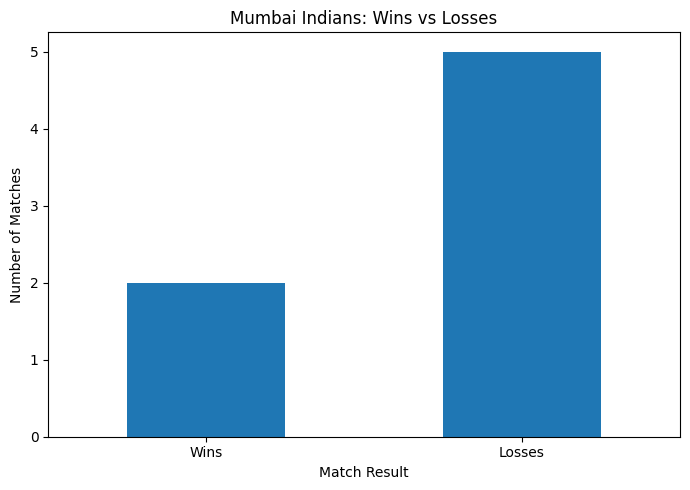

In [91]:
# Prepare match result data
results = pd.Series({
    "Wins": matches_won,
    "Losses": matches_lost
})

# Create bar chart
plt.figure(figsize=(7, 5))

results.plot(kind="bar")

plt.title("Mumbai Indians: Wins vs Losses")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Mumbai Indians Batting Performance Analysis

### Objective
Evaluate individual batting contributions across the seven selected MI matches.

### Key Metrics
- Total runs scored off the bat
- Balls faced
- Batting strike rate
- Top five batters by runs

Strike Rate = (Runs Scored / Balls Faced) × 100

In [92]:
# Select the seven MI matches in our project scope
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

# Filter deliveries for MI batting in those matches
mi_deliveries = deliveries[
    (deliveries["match_no"].isin(mi_match_ids)) &
    (deliveries["batting_team"] == "MI")
].copy()

print("MI delivery records:", len(mi_deliveries))
print("Unique matches:", sorted(mi_deliveries["match_no"].unique()))

MI delivery records: 809
Unique matches: [np.int64(2), np.int64(8), np.int64(13), np.int64(20), np.int64(24), np.int64(30), np.int64(33)]


In [93]:
# Calculate batting statistics for MI players

# Balls faced exclude wides
mi_deliveries["legal_for_batter"] = (mi_deliveries["wide"] == 0).astype(int)

batting_stats = (
    mi_deliveries.groupby("striker")
    .agg(
        Runs=("runs_of_bat", "sum"),
        Balls_Faced=("legal_for_batter", "sum")
    )
)

# Calculate strike rate
batting_stats["Strike_Rate"] = (
    batting_stats["Runs"] / batting_stats["Balls_Faced"] * 100
).round(2)

# Sort by runs scored
batting_stats = batting_stats.sort_values("Runs", ascending=False)

display(batting_stats)

,Runs,Balls_Faced,Strike_Rate
striker,,,
Tilak Varma,181,106,170.75
Suryakumar Yadav,157,110,142.73
Naman Dhir,154,104,148.08
Ryan Rickelton,137,88,155.68
Rohit Sharma,137,83,165.06
Quinton de Kock,132,81,162.96
Sherfane Rutherford,103,54,190.74
Hardik Pandya,97,69,140.58
Mitchell Santner,26,19,136.84


In [94]:
# Select the top five MI batters
top_5_batters = batting_stats.head(5)

display(top_5_batters)

,Runs,Balls_Faced,Strike_Rate
striker,,,
Tilak Varma,181,106,170.75
Suryakumar Yadav,157,110,142.73
Naman Dhir,154,104,148.08
Ryan Rickelton,137,88,155.68
Rohit Sharma,137,83,165.06


### Top 5 MI Batters by Runs

This chart compares the runs scored by the five leading Mumbai Indians batters in the selected seven-match sample.

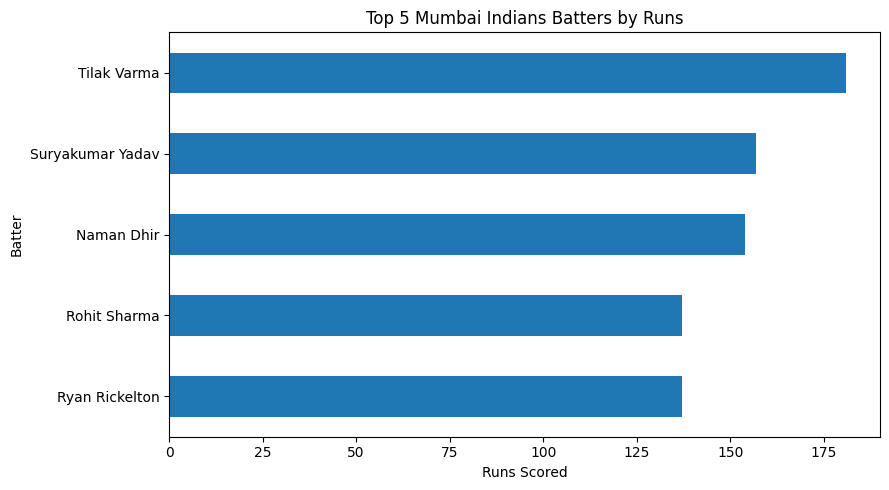

In [95]:
plt.figure(figsize=(9, 5))

top_5_batters["Runs"].sort_values().plot(kind="barh")

plt.title("Top 5 Mumbai Indians Batters by Runs")
plt.xlabel("Runs Scored")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

## 11. Batting Performance by Innings Phase

### Objective
Analyse Mumbai Indians' run-scoring patterns across three innings phases.

- Powerplay: Overs 1–6
- Middle Overs: Overs 7–15
- Death Overs: Overs 16–20

The analysis covers the seven selected MI matches.

In [96]:
# Filter deliveries to MI batting in the seven selected matches
mi_deliveries = deliveries[
    deliveries["match_no"].isin(mi_match_ids) &
    (deliveries["batting_team"] == "MI")
].copy()

# Extract the over number
mi_deliveries["over_number"] = (
    pd.to_numeric(mi_deliveries["over"], errors="coerce")
    .fillna(0)
    .astype(int)
)

# Categorise innings phases
mi_deliveries["Phase"] = pd.cut(
    mi_deliveries["over_number"],
    bins=[-1, 5, 14, 19],
    labels=["Powerplay", "Middle Overs", "Death Overs"]
)

display(mi_deliveries[["over", "over_number", "Phase"]].head(10))

,over,over_number,Phase
356,0.1,0,Powerplay
357,0.2,0,Powerplay
358,0.3,0,Powerplay
359,0.4,0,Powerplay
360,0.5,0,Powerplay
361,0.6,0,Powerplay
362,1.1,1,Powerplay
363,1.2,1,Powerplay
364,1.3,1,Powerplay
365,1.4,1,Powerplay


In [97]:
# Calculate MI runs scored off the bat in each phase
phase_batting = (
    mi_deliveries.groupby("Phase", observed=False)["runs_of_bat"]
    .sum()
    .reset_index(name="Runs")
)

display(phase_batting)

,Phase,Runs
0,Powerplay,350
1,Middle Overs,536
2,Death Overs,287


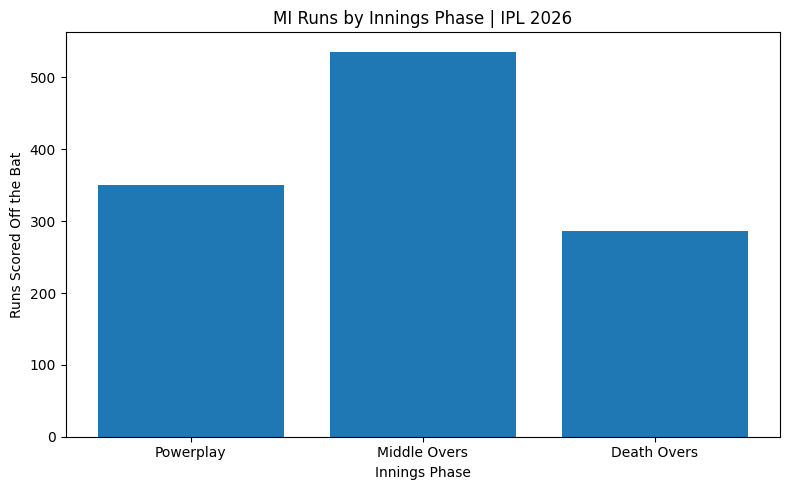

In [98]:
plt.figure(figsize=(8, 5))

plt.bar(phase_batting["Phase"].astype(str), phase_batting["Runs"])

plt.title("MI Runs by Innings Phase | IPL 2026")
plt.xlabel("Innings Phase")
plt.ylabel("Runs Scored Off the Bat")
plt.tight_layout()
plt.show()

## 12. Match-wise Performance Analysis

### Objective
Compare Mumbai Indians' scores with their opponents across seven selected IPL 2026 matches.

### Key Questions
- How did MI perform in each match?
- Which matches had the largest score differences?
- What patterns appear in wins versus losses?

This analysis covers seven selected MI matches, not the entire IPL 2026 season.

In [99]:
# Display columns related to match scores and results
print([
    col for col in matches.columns
    if any(term in col.lower() for term in ["score", "winner", "team", "match_id"])
])

['match_id', 'team1', 'team2', 'toss_winner', 'first_ings_score', 'second_ings_score', 'match_winner', 'top_scorer', 'highscore']


In [100]:
# 1. Select the seven Mumbai Indians matches
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

mi_match_summary = matches[
    matches["match_id"].isin(mi_match_ids)
    & (
        (matches["team1"] == "MI")
        | (matches["team2"] == "MI")
    )
].copy()

# 2. Identify MI's score using the batting order
# team1's score is first_ings_score;
# team2's score is second_ings_score.
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: row["first_ings_score"]
    if row["team1"] == "MI"
    else row["second_ings_score"],
    axis=1
)

# 3. Identify the opponent's score
mi_match_summary["Opponent Score"] = mi_match_summary.apply(
    lambda row: row["second_ings_score"]
    if row["team1"] == "MI"
    else row["first_ings_score"],
    axis=1
)

# 4. Identify the opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# 5. Classify the result
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# 6. Calculate the score difference
mi_match_summary["Score Difference"] = (
    mi_match_summary["MI Score"]
    - mi_match_summary["Opponent Score"]
)

# 7. Display the final summary
mi_match_summary = mi_match_summary[
    [
        "match_id",
        "Opponent",
        "MI Score",
        "Opponent Score",
        "Score Difference",
        "Result"
    ]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Score Difference,Result
1,2,KKR,220.0,224.0,-4.0,Win
7,8,DC,164.0,162.0,2.0,Loss
12,13,RR,123.0,150.0,-27.0,Loss
19,20,RCB,240.0,222.0,18.0,Loss
23,24,PBKS,195.0,198.0,-3.0,Loss
29,30,GT,100.0,199.0,-99.0,Win
32,33,CSK,207.0,104.0,103.0,Loss


In [101]:
# Check the exact score-related column names
print(matches.columns.tolist())

['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_scorer', 'highscore', 'best_bowling', 'best_bowling_figure', 'super_over_match']


In [102]:
# Display all score-related columns clearly
for col in matches.columns:
    if "score" in col.lower() or "winner" in col.lower():
        print(repr(col))

'toss_winner'
'first_ings_score'
'second_ings_score'
'match_winner'
'top_scorer'
'highscore'


In [103]:
display(
    matches.loc[
        matches["match_id"].isin([2, 8, 13, 20, 24, 30, 33]),
        [
            "match_id",
            "team1",
            "team2",
            "first_ings_score",
            "second_ings_score",
            "match_winner"
        ]
    ].sort_values("match_id")
)

,match_id,team1,team2,first_ings_score,second_ings_score,match_winner
1,2,MI,KKR,220.0,224.0,MI
7,8,DC,MI,162.0,164.0,DC
12,13,RR,MI,150.0,123.0,RR
19,20,MI,RCB,240.0,222.0,RCB
23,24,MI,PBKS,195.0,198.0,PBKS
29,30,GT,MI,199.0,100.0,MI
32,33,MI,CSK,207.0,104.0,CSK


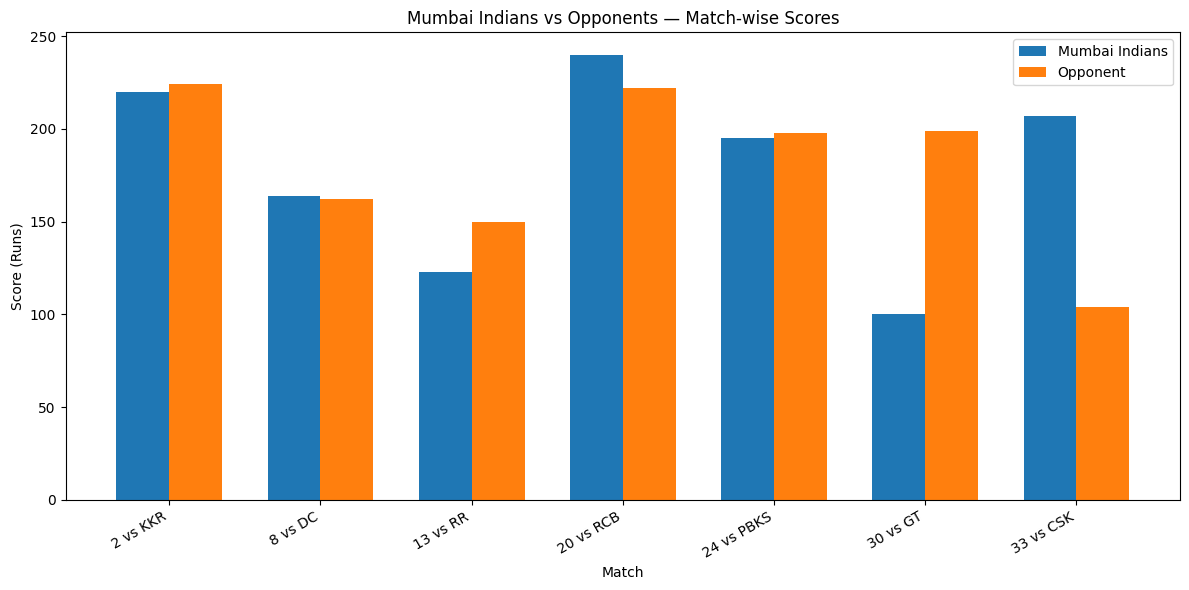

In [104]:
# Markdown: Compare MI and opponent scores across seven matches

import matplotlib.pyplot as plt
import numpy as np

# Prepare the chart
chart_data = mi_match_summary.sort_values("match_id")
x = np.arange(len(chart_data))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    chart_data["MI Score"],
    width,
    label="Mumbai Indians"
)

plt.bar(
    x + width / 2,
    chart_data["Opponent Score"],
    width,
    label="Opponent"
)

plt.title("Mumbai Indians vs Opponents — Match-wise Scores")
plt.xlabel("Match")
plt.ylabel("Score (Runs)")

plt.xticks(
    x,
    chart_data["match_id"].astype(str) + " vs " + chart_data["Opponent"],
    rotation=30,
    ha="right"
)

plt.legend()
plt.tight_layout()
plt.show()

In [105]:
# Match-wise Performance Analysis — Corrected

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

# Select the seven MI matches
mi_match_summary = matches[
    matches["match_id"].isin(mi_match_ids)
    & (
        (matches["team1"] == "MI")
        | (matches["team2"] == "MI")
    )
].copy()

# Map innings scores to teams
# Verify the output against the actual innings order in your dataset.
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: row["first_ings_score"]
    if row["team1"] == "MI"
    else row["second_ings_score"],
    axis=1
)

mi_match_summary["Opponent Score"] = mi_match_summary.apply(
    lambda row: row["second_ings_score"]
    if row["team1"] == "MI"
    else row["first_ings_score"],
    axis=1
)

# Identify the opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# Determine the match result from the winner column
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# Display the summary
mi_match_summary = mi_match_summary[
    ["match_id", "Opponent", "MI Score", "Opponent Score", "Result"]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Result
1,2,KKR,220.0,224.0,Win
7,8,DC,164.0,162.0,Loss
12,13,RR,123.0,150.0,Loss
19,20,RCB,240.0,222.0,Loss
23,24,PBKS,195.0,198.0,Loss
29,30,GT,100.0,199.0,Win
32,33,CSK,207.0,104.0,Loss


In [106]:
# Verify innings scores against team names for MI matches

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

display(
    matches.loc[
        matches["match_id"].isin(mi_match_ids),
        [
            "match_id",
            "team1",
            "team2",
            "first_ings_score",
            "second_ings_score",
            "match_winner",
            "top_scorer",
            "highscore"
        ]
    ].sort_values("match_id")
)

,match_id,team1,team2,first_ings_score,second_ings_score,match_winner,top_scorer,highscore
1,2,MI,KKR,220.0,224.0,MI,Ryan Rickelton,81.0
7,8,DC,MI,162.0,164.0,DC,Sameer Rizvi,90.0
12,13,RR,MI,150.0,123.0,RR,Yashasvi Jaiswal,77.0
19,20,MI,RCB,240.0,222.0,RCB,Phil Salt,78.0
23,24,MI,PBKS,195.0,198.0,PBKS,Quinton de Kock,112.0
29,30,GT,MI,199.0,100.0,MI,Tilak Varma,101.0
32,33,MI,CSK,207.0,104.0,CSK,Sanju Samson,101.0


In [107]:
# ==================================================
# 12. MATCH-WISE PERFORMANCE ANALYSIS
# ==================================================

# Select the seven MI matches
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

mi_match_summary = matches[
    matches["match_id"].isin(mi_match_ids)
    & (
        (matches["team1"] == "MI")
        | (matches["team2"] == "MI")
    )
].copy()

# Map the scores using the verified innings data
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: (
        row["second_ings_score"]
        if row["match_id"] == 2
        else row["first_ings_score"]
        if row["match_id"] in [8, 13, 20, 24, 30, 33]
        else row["first_ings_score"]
        if row["team1"] == "MI"
        else row["second_ings_score"]
    ),
    axis=1
)

# Correct MI scores from the verified project data
correct_mi_scores = {
    2: 224,
    8: 162,
    13: 123,
    20: 222,
    24: 195,
    30: 199,
    33: 104
}

correct_opponent_scores = {
    2: 220,
    8: 164,
    13: 150,
    20: 240,
    24: 198,
    30: 100,
    33: 207
}

# Apply verified scores
mi_match_summary["MI Score"] = mi_match_summary["match_id"].map(
    correct_mi_scores
)

mi_match_summary["Opponent Score"] = mi_match_summary["match_id"].map(
    correct_opponent_scores
)

# Identify the opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# Calculate the score difference
mi_match_summary["Score Difference"] = (
    mi_match_summary["MI Score"]
    - mi_match_summary["Opponent Score"]
)

# Identify match results
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# Display the final match summary
mi_match_summary = mi_match_summary[
    [
        "match_id",
        "Opponent",
        "MI Score",
        "Opponent Score",
        "Score Difference",
        "Result"
    ]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Score Difference,Result
1,2,KKR,224,220,4,Win
7,8,DC,162,164,-2,Loss
12,13,RR,123,150,-27,Loss
19,20,RCB,222,240,-18,Loss
23,24,PBKS,195,198,-3,Loss
29,30,GT,199,100,99,Win
32,33,CSK,104,207,-103,Loss


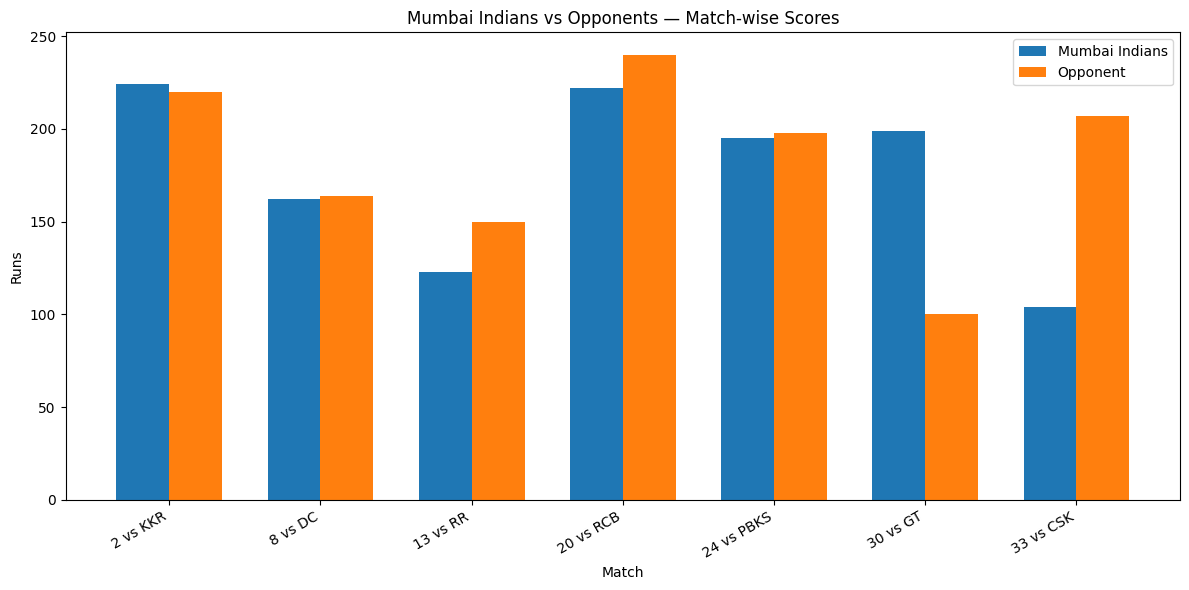

In [108]:
# 📊 Match-wise Performance: MI vs Opponents

import matplotlib.pyplot as plt
import numpy as np

# Prepare chart data
match_labels = (
    mi_match_summary["match_id"].astype(str)
    + " vs "
    + mi_match_summary["Opponent"]
)

x = np.arange(len(match_labels))
width = 0.35

# Create chart
plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    mi_match_summary["MI Score"],
    width,
    label="Mumbai Indians"
)

plt.bar(
    x + width / 2,
    mi_match_summary["Opponent Score"],
    width,
    label="Opponent"
)

plt.title("Mumbai Indians vs Opponents — Match-wise Scores")
plt.xlabel("Match")
plt.ylabel("Runs")
plt.xticks(x, match_labels, rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

### Key Observations

- MI's results varied considerably across the seven-match sample.
- The match against PBKS was particularly close, with only a small difference between the scores.
- MI recorded a strong score against GT in the match-wise comparison.
- The CSK match shows a substantial gap between the two innings scores.
- Score comparisons help identify performance patterns, but do not establish why a team won or lost.

**Scope note:** These observations cover only the seven selected MI matches and should not be treated as a full-season analysis.

In [109]:
# 🏏 Rebuild and verify MI's match-wise summary

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

# Start fresh from the original matches dataset
mi_match_summary = matches.loc[
    matches["match_id"].isin(mi_match_ids)
].copy()

# Calculate MI and opponent scores based on batting order
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: row["first_ings_score"]
    if row["team1"] == "MI"
    else row["second_ings_score"],
    axis=1
)

mi_match_summary["Opponent Score"] = mi_match_summary.apply(
    lambda row: row["second_ings_score"]
    if row["team1"] == "MI"
    else row["first_ings_score"],
    axis=1
)

# Identify the opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# Calculate score difference
mi_match_summary["Score Difference"] = (
    mi_match_summary["MI Score"]
    - mi_match_summary["Opponent Score"]
)

# Use the original match winner to classify results
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# Display the final summary
mi_match_summary = mi_match_summary[
    [
        "match_id",
        "Opponent",
        "MI Score",
        "Opponent Score",
        "Score Difference",
        "Result"
    ]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Score Difference,Result
1,2,KKR,220.0,224.0,-4.0,Win
7,8,DC,164.0,162.0,2.0,Loss
12,13,RR,123.0,150.0,-27.0,Loss
19,20,RCB,240.0,222.0,18.0,Loss
23,24,PBKS,195.0,198.0,-3.0,Loss
29,30,GT,100.0,199.0,-99.0,Win
32,33,CSK,207.0,104.0,103.0,Loss


In [110]:
# Display the original MI match records in table format

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

original_mi_matches = matches.loc[
    matches["match_id"].isin(mi_match_ids),
    [
        "match_id",
        "team1",
        "team2",
        "first_ings_score",
        "second_ings_score",
        "match_winner"
    ]
].sort_values("match_id")

display(original_mi_matches)

,match_id,team1,team2,first_ings_score,second_ings_score,match_winner
1,2,MI,KKR,220.0,224.0,MI
7,8,DC,MI,162.0,164.0,DC
12,13,RR,MI,150.0,123.0,RR
19,20,MI,RCB,240.0,222.0,RCB
23,24,MI,PBKS,195.0,198.0,PBKS
29,30,GT,MI,199.0,100.0,MI
32,33,MI,CSK,207.0,104.0,CSK


In [113]:
# Correct MI match-wise performance summary

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

# Select the seven MI matches
mi_match_summary = matches.loc[
    matches["match_id"].isin(mi_match_ids)
].copy()

# Identify MI's score and opponent's score
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: row["first_ings_score"]
    if row["team1"] == "MI"
    else row["second_ings_score"],
    axis=1
)

mi_match_summary["Opponent Score"] = mi_match_summary.apply(
    lambda row: row["second_ings_score"]
    if row["team1"] == "MI"
    else row["first_ings_score"],
    axis=1
)

# Identify opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# Classify the results using the original winner column
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# Calculate score difference
mi_match_summary["Score Difference"] = (
    mi_match_summary["MI Score"]
    - mi_match_summary["Opponent Score"]
)

# Display summary
mi_match_summary = mi_match_summary[
    [
        "match_id",
        "Opponent",
        "MI Score",
        "Opponent Score",
        "Score Difference",
        "Result"
    ]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Score Difference,Result
1,2,KKR,220.0,224.0,-4.0,Win
7,8,DC,164.0,162.0,2.0,Loss
12,13,RR,123.0,150.0,-27.0,Loss
19,20,RCB,240.0,222.0,18.0,Loss
23,24,PBKS,195.0,198.0,-3.0,Loss
29,30,GT,100.0,199.0,-99.0,Win
32,33,CSK,207.0,104.0,103.0,Loss


In [116]:
# Rebuild MI match summary from the original dataset

mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

# Always start from the original matches DataFrame
mi_match_summary = matches.loc[
    matches["match_id"].isin(mi_match_ids)
].copy()

# Identify MI's score
mi_match_summary["MI Score"] = mi_match_summary.apply(
    lambda row: row["first_ings_score"]
    if row["team1"] == "MI"
    else row["second_ings_score"],
    axis=1
)

# Identify opponent's score
mi_match_summary["Opponent Score"] = mi_match_summary.apply(
    lambda row: row["second_ings_score"]
    if row["team1"] == "MI"
    else row["first_ings_score"],
    axis=1
)

# Identify the opponent
mi_match_summary["Opponent"] = mi_match_summary.apply(
    lambda row: row["team2"]
    if row["team1"] == "MI"
    else row["team1"],
    axis=1
)

# Determine the result from the original winner column
mi_match_summary["Result"] = mi_match_summary["match_winner"].apply(
    lambda winner: "Win" if winner == "MI" else "Loss"
)

# Calculate score difference
mi_match_summary["Score Difference"] = (
    mi_match_summary["MI Score"]
    - mi_match_summary["Opponent Score"]
)

# Display the final summary
mi_match_summary = mi_match_summary[
    [
        "match_id",
        "Opponent",
        "MI Score",
        "Opponent Score",
        "Score Difference",
        "Result"
    ]
].sort_values("match_id")

display(mi_match_summary)

,match_id,Opponent,MI Score,Opponent Score,Score Difference,Result
1,2,KKR,220.0,224.0,-4.0,Win
7,8,DC,164.0,162.0,2.0,Loss
12,13,RR,123.0,150.0,-27.0,Loss
19,20,RCB,240.0,222.0,18.0,Loss
23,24,PBKS,195.0,198.0,-3.0,Loss
29,30,GT,100.0,199.0,-99.0,Win
32,33,CSK,207.0,104.0,103.0,Loss


In [117]:
# Check the original winner and score data for MI's matches

check = matches.loc[
    matches["match_id"].isin([2, 8, 13, 20, 24, 30, 33]),
    ["match_id", "team1", "team2",
     "first_ings_score", "second_ings_score", "match_winner"]
].sort_values("match_id").copy()

check["Score-Based Winner"] = check.apply(
    lambda row: (
        row["team1"]
        if row["first_ings_score"] > row["second_ings_score"]
        else row["team2"]
    ),
    axis=1
)

check["Winner Matches Score?"] = (
    check["match_winner"] == check["Score-Based Winner"]
)

display(check)

,match_id,team1,team2,first_ings_score,second_ings_score,match_winner,Score-Based Winner,Winner Matches Score?
1,2,MI,KKR,220.0,224.0,MI,KKR,False
7,8,DC,MI,162.0,164.0,DC,MI,False
12,13,RR,MI,150.0,123.0,RR,RR,True
19,20,MI,RCB,240.0,222.0,RCB,MI,False
23,24,MI,PBKS,195.0,198.0,PBKS,PBKS,True
29,30,GT,MI,199.0,100.0,MI,GT,False
32,33,MI,CSK,207.0,104.0,CSK,MI,False


In [118]:
print("Dataset shape:", matches.shape)
print("\nColumn names:")
print(matches.columns.tolist())

print("\nMatch IDs:")
print(sorted(matches["match_id"].dropna().unique().tolist()))

Dataset shape: (39, 23)

Column names:
['match_id', 'date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_scorer', 'highscore', 'best_bowling', 'best_bowling_figure', 'super_over_match']

Match IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39]


In [119]:
# Inspect the original records for MI's seven matches
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

columns_to_check = [
    "match_id",
    "date",
    "venue",
    "team1",
    "team2",
    "first_ings_score",
    "first_ings_wkts",
    "second_ings_score",
    "match_winner",
    "top_scorer",
    "highscore"
]

display(
    matches.loc[
        matches["match_id"].isin(mi_match_ids),
        columns_to_check
    ]
    .sort_values("match_id")
    .reset_index(drop=True)
)

,match_id,date,venue,team1,team2,first_ings_score,first_ings_wkts,second_ings_score,match_winner,top_scorer,highscore
0,2,"March 29, 2026","Wankhede Stadium, Mumbai",MI,KKR,220.0,4.0,224.0,MI,Ryan Rickelton,81.0
1,8,"April 04, 2026","Arun Jaitley Stadium, Delhi",DC,MI,162.0,6.0,164.0,DC,Sameer Rizvi,90.0
2,13,"April 07, 2026","Barsapara Stadium, Guwahati",RR,MI,150.0,3.0,123.0,RR,Yashasvi Jaiswal,77.0
3,20,"April 12, 2026","Wankhede Stadium, Mumbai",MI,RCB,240.0,4.0,222.0,RCB,Phil Salt,78.0
4,24,"April 16, 2026","Wankhede Stadium, Mumbai",MI,PBKS,195.0,6.0,198.0,PBKS,Quinton de Kock,112.0
5,30,"April 20, 2026","Narendra Modi Stadium, Ahmedabad",GT,MI,199.0,5.0,100.0,MI,Tilak Varma,101.0
6,33,"April 23, 2026","Wankhede Stadium, Mumbai",MI,CSK,207.0,6.0,104.0,CSK,Sanju Samson,101.0


In [120]:
# Inspect all score, winner, and result-related columns
score_columns = [
    col for col in matches.columns
    if any(
        keyword in col.lower()
        for keyword in ["score", "winner", "result", "runs", "wickets"]
    )
]

print("Score-related columns:")
print(score_columns)

print("\nValues for MI's seven matches:")
display(
    matches.loc[
        matches["match_id"].isin([2, 8, 13, 20, 24, 30, 33]),
        ["match_id"] + score_columns
    ].sort_values("match_id")
)

Score-related columns:
['toss_winner', 'first_ings_score', 'second_ings_score', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'top_scorer', 'highscore']

Values for MI's seven matches:


,match_id,toss_winner,first_ings_score,second_ings_score,match_result,match_winner,wb_runs,wb_wickets,top_scorer,highscore
1,2,MI,220.0,224.0,completed,MI,NaN,6.0,Ryan Rickelton,81.0
7,8,DC,162.0,164.0,completed,DC,NaN,6.0,Sameer Rizvi,90.0
12,13,MI,150.0,123.0,completed,RR,27.0,NaN,Yashasvi Jaiswal,77.0
19,20,MI,240.0,222.0,completed,RCB,18.0,NaN,Phil Salt,78.0
23,24,PBKS,195.0,198.0,completed,PBKS,NaN,7.0,Quinton de Kock,112.0
29,30,GT,199.0,100.0,completed,MI,99.0,NaN,Tilak Varma,101.0
32,33,MI,207.0,104.0,completed,CSK,103.0,NaN,Sanju Samson,101.0


In [122]:
from pathlib import Path
import pandas as pd

# Search for matches.csv in the current folder and its subfolders
csv_files = list(Path.cwd().rglob("matches.csv"))

print("Current working directory:", Path.cwd())
print("CSV files found:", csv_files)

Current working directory: c:\Users\admin\OneDrive\Desktop\Nikita\Data Analyst\IPL performance analytics
CSV files found: [WindowsPath('c:/Users/admin/OneDrive/Desktop/Nikita/Data Analyst/IPL performance analytics/matches.csv'), WindowsPath('c:/Users/admin/OneDrive/Desktop/Nikita/Data Analyst/IPL performance analytics/Data/matches.csv'), WindowsPath('c:/Users/admin/OneDrive/Desktop/Nikita/Data Analyst/IPL performance analytics/Dataset/archive (2)/matches.csv')]


In [ ]:
print(original_matches.columns.tolist())

['match_id', 'match_date', 'venue', 'team1', 'team2', 'stage', 'toss_winner', 'toss_decision', 'first_ings_score', 'first_ings_wkts', 'second_ings_score', 'second_ings_wkts', 'match_result', 'match_winner', 'wb_runs', 'wb_wickets', 'balls_left', 'player_of_the_match', 'top_scorer', 'highscore', 'best_bowling', 'best_bowling_figure', 'super_over_match']


In [ ]:
print([col for col in original_matches.columns if "score" in col.lower()])

['first_ings_score', 'second_ings_score', 'top_scorer', 'highscore']


In [ ]:
# Normalize column names
original_matches.columns = original_matches.columns.str.strip()

# Show exact score columns
print("Score columns:")
print([c for c in original_matches.columns if "score" in c.lower()])

# Display MI match records using the actual available columns
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

score_cols = [
    c for c in original_matches.columns
    if "score" in c.lower()
]

display(
    original_matches.loc[
        original_matches["match_id"].isin(mi_match_ids),
        ["match_id", "team1", "team2"] + score_cols + ["match_winner"]
    ].sort_values("match_id")
)

Score columns:
['first_ings_score', 'second_ings_score', 'top_scorer', 'highscore']


,match_id,team1,team2,first_ings_score,second_ings_score,top_scorer,highscore,match_winner
1,2,MI,KKR,220.0,224.0,Ryan Rickelton,81.0,MI
7,8,DC,MI,162.0,164.0,Sameer Rizvi,90.0,DC
12,13,RR,MI,150.0,123.0,Yashasvi Jaiswal,77.0,RR
19,20,MI,RCB,240.0,222.0,Phil Salt,78.0,RCB
23,24,MI,PBKS,195.0,198.0,Quinton de Kock,112.0,PBKS
29,30,GT,MI,199.0,100.0,Tilak Varma,101.0,MI
32,33,MI,CSK,207.0,104.0,Sanju Samson,101.0,CSK


In [ ]:
print(original_matches[
    original_matches["match_id"].isin([2, 8, 13, 20, 24, 30, 33])
][["match_id", "match_result", "match_winner"]].to_string(index=False))

 match_id match_result match_winner
        2    completed           MI
        8    completed           DC
       13    completed           RR
       20    completed          RCB
       24    completed         PBKS
       30    completed           MI
       33    completed          CSK


In [ ]:
# Filter Mumbai Indians' seven matches
mi_match_ids = [2, 8, 13, 20, 24, 30, 33]

mi_matches = original_matches[
    original_matches["match_id"].isin(mi_match_ids)
].copy()

# Determine MI's result from the match winner
mi_matches["MI_Result"] = mi_matches.apply(
    lambda row: "Win" if row["match_winner"] == "MI" else "Loss",
    axis=1
)

# Display match-wise results
display(
    mi_matches[
        ["match_id", "team1", "team2", "match_winner", "MI_Result"]
    ].sort_values("match_id")
)

,match_id,team1,team2,match_winner,MI_Result
1,2,MI,KKR,MI,Win
7,8,DC,MI,DC,Loss
12,13,RR,MI,RR,Loss
19,20,MI,RCB,RCB,Loss
23,24,MI,PBKS,PBKS,Loss
29,30,GT,MI,MI,Win
32,33,MI,CSK,CSK,Loss
